# Vertical Auto Encoder
## Configurations and initializations

This section loads libraries and configurations for various tasks for this course

In [ ]:
## Standard libraries
import os
import math
import numpy as np
import pandas as pd
from collections import defaultdict

## Imports for plotting
import matplotlib.pyplot as plt
plt.set_cmap('cividis')
%matplotlib inline
from IPython.display import set_matplotlib_formats
%config InlineBackend.figure_formats = ['svg', 'pdf']
from matplotlib.colors import to_rgb
import seaborn as sns

## Progress bar
from tqdm.notebook import tqdm

## PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import torch.optim as optim

# Torchvision
import torchvision
from torchvision.datasets import MNIST
from torchvision import transforms

# Path to the folder where the datasets are/should be downloaded (e.g. MNIST)
DATASET_PATH = "../data"

# Path to the folder where the models are saved
CHECKPOINT_PATH = "./"

# Ensure that all operations are deterministic on GPU (if used) for reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Fetching the device that will be used throughout this notebook
device = torch.device("cpu") if not torch.cuda.is_available() else torch.device("cuda:0")
print("Using device", device)

Using device cuda:0


<Figure size 640x480 with 0 Axes>

In [ ]:
import torchvision.transforms as transforms
import torch
import random

class AddUniformNoise:
    def __call__(self, tensor):
        # Add uniform noise in [0, 1)
        noise = torch.rand_like(tensor)
        return (tensor * 255.0 + noise) / 256.0

In [ ]:
# Transformations applied on each image => only make them a tensor
# In order to consider the pixel values as continuous, you should cast them to a oat type, add uniform noise
# in the range of [0,1], and then scale them from [0,256] to [0,1].
transform = transforms.Compose([
    transforms.ToTensor(),        # Converts to float32 and scales to [0, 1]
    AddUniformNoise(),           # Adds noise and rescales to [0, 1)
])

# Loading the training dataset. We need to split it into a training and validation part
train_dataset = MNIST(root=DATASET_PATH, train=True, transform=transform, download=True)

train_set, val_set = torch.utils.data.random_split(train_dataset, [50000, 10000])

# Loading the test set
test_set = MNIST(root=DATASET_PATH, train=False, transform=transform, download=True)

# We define a set of data loaders that we can use for various purposes later.
train_loader = data.DataLoader(train_set, batch_size=128, shuffle=True, drop_last=True, pin_memory=True, num_workers=0)
val_loader = data.DataLoader(val_set, batch_size=128, shuffle=False, drop_last=False, num_workers=0)
test_loader = data.DataLoader(test_set, batch_size=128, shuffle=False, drop_last=False, num_workers=0)

print('Train size:', len(train_loader.dataset))
print('Validation size:', len(val_loader.dataset))
print('Test size:', len(test_loader.dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 484kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.90MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.1MB/s]

Train size: 50000
Validation size: 10000
Test size: 10000


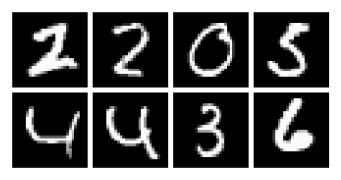

In [ ]:
def show_imgs(imgs):
    num_imgs = imgs.shape[0] if isinstance(imgs, torch.Tensor) else len(imgs)
    nrow = min(num_imgs, 4)
    ncol = int(math.ceil(num_imgs/nrow))
    imgs = torchvision.utils.make_grid(imgs, nrow=nrow, pad_value=128)
    imgs = imgs.clamp(min=0, max=1)
    np_imgs = imgs.cpu().numpy()
    plt.figure(figsize=(1.5*nrow, 1.5*ncol))
    plt.imshow(np.transpose(np_imgs, (1,2,0)), interpolation='nearest')
    plt.axis('off')
    plt.show()

show_imgs([train_set[i][0] for i in range(8)])

In [ ]:
class Encoder2(nn.Module):
    def __init__(self, latent_dim):
        super(Encoder2, self).__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 4, stride=2, padding=1),  # 28 → 14
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2, padding=1), # 14 → 7
            nn.ReLU(),
            nn.Conv2d(64, 128, 3, stride=1, padding=1),
            nn.ReLU()
        )

        self.flatten = nn.Flatten()
        self.fc = nn.Sequential(
            nn.Linear(128 * 7 * 7, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(512, latent_dim)
        self.fc_logvar = nn.Linear(512, latent_dim)

    def reparameterization(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        x = self.conv(x)
        x = self.flatten(x)
        x = self.fc(x)
        mu = self.fc_mu(x)
        log_var = self.fc_logvar(x)
        z = self.reparameterization(mu, log_var)
        return mu, log_var, z


In [ ]:
class Decoder2(nn.Module):
    def __init__(self, latent_dim):
        super(Decoder2, self).__init__()

        self.latent_dim = latent_dim

        # FC Layers: More capacity
        self.fc = nn.Sequential(
            nn.Linear(latent_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.ReLU(),
            nn.Linear(1024, 128 * 7 * 7),
            nn.ReLU()
        )

        self.unflatten = nn.Unflatten(1, (128, 7, 7))

        # ConvTranspose Layers: Better reconstruction with additional block
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),  # 7→14
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),   # 14→28
            nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 1, 3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, z):
        x = self.fc(z)
        x = self.unflatten(x)
        x = self.deconv(x)
        return x


In [ ]:
class VAE(nn.Module):

    def __init__(self, latent_dim):
        super().__init__()

        self.latent_dim = latent_dim

        self.logs = defaultdict(list)
        self.encoder = Encoder2(latent_dim)
        self.decoder = Decoder2(latent_dim)

    def log(self, key, value):
        self.logs[key].append(value)
        return value

    def forward(self, x):
        mu, log_var, z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction, mu, log_var, z

    def calc_elbo(self, batch):
        imgs = batch.to(device)
        recon, mu, log_var, _ = self.forward(imgs)
        var = 0.01  # fixed variance

        # MSE reconstruction loss with constant variance
        rec_loss = F.mse_loss(recon, imgs, reduction='sum') / (2 * var * imgs.size(0))

        # KL divergence
        KLD = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp()) / imgs.size(0)

        elbo = -(rec_loss + KLD)
        return elbo, rec_loss, KLD

    @torch.no_grad()
    def sample(self, num_samples):
        z = torch.randn(num_samples, self.latent_dim).to(device)
        samples = self.decoder(z)
        return samples

    def training_step(self, batch):
        elbo, rec_loss, KLD = self.calc_elbo(batch)
        loss = -elbo
        # Log losses
        self.log('train_elbo', loss.item())
        self.log('train_recon', rec_loss.item())
        self.log('train_KLD', KLD.item())
        return loss

    @torch.no_grad()
    def validation_step(self, loader):
        loss_obj = []
        for imgs, _ in tqdm(loader, leave=False):
          imgs = imgs.to(device)
          loss_obj.append(self.calc_elbo(imgs))

        loss_obj = torch.tensor(loss_obj)
        elbo, rec_loss, KLD = loss_obj.mean(dim=0)
        loss = -elbo
        # Log losses
        self.log('val_elbo', loss.item())
        self.log('val_recon', rec_loss.item())
        self.log('val_KLD', KLD.item())

        return loss

    @torch.no_grad()
    def test_step(self, loader):
        loss_obj = []
        for imgs, _ in tqdm(loader, leave=False):
          imgs = imgs.to(device)
          loss_obj.append(self.calc_elbo(imgs))

        loss_obj = torch.tensor(loss_obj)
        elbo, rec_loss, KLD = loss_obj.mean(dim=0)
        loss = -elbo
        # Log losses
        self.log('test_elbo', loss.item())
        self.log('test_recon', rec_loss.item())
        self.log('test_KLD', KLD.item())

        return loss

## Model Architecture:
It consists of Encoder and Decoder:
1. Encoder: 3 Conv layers (where the first 2 with stride = 2 and the last with stride = 1), followed by flattening layer, then 2 fully connected layers, after that we extract the mu and var vectors.

2. Decoder: 3 fully connceted layers, followd by 2 deconv layers and 2 conv layers, at the end sigmoid activation.

## Model Training

In [ ]:
model = VAE(latent_dim=32)
model = model.to(device)
print("Num params: {:,}".format(sum(p.numel() for p in model.parameters())))

model = torch.compile(model.to(device))

optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.StepLR(optimizer, 1, gamma=0.99)
epochs = 20

Num params: 14,228,129


The latent dim being used is 32, we found out that this value gave the best results, both in terms of generating and learning.

In [ ]:
train_elbos, train_recons, train_klds = [], [], []
val_elbos, val_recons, val_klds = [], [], []

for epoch in range(epochs):
    model.train()
    losses = []

    for imgs, _ in tqdm(train_loader, leave=False):
        imgs = imgs.to(device)
        optimizer.zero_grad()
        loss = model.training_step(imgs)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    scheduler.step()

    # Aggregate epoch-wise averages
    train_elbo = sum(model.logs['train_elbo']) / len(model.logs['train_elbo'])
    train_recon = sum(model.logs['train_recon']) / len(model.logs['train_recon'])
    train_kld = sum(model.logs['train_KLD']) / len(model.logs['train_KLD'])

    train_elbos.append(train_elbo)
    train_recons.append(train_recon)
    train_klds.append(train_kld)

    model.logs['train_elbo'].clear()
    model.logs['train_recon'].clear()
    model.logs['train_KLD'].clear()

    # Validation
    val_loss = model.validation_step(val_loader)
    val_elbo = model.logs['val_elbo'][-1]
    val_recon = model.logs['val_recon'][-1]
    val_kld = model.logs['val_KLD'][-1]

    val_elbos.append(val_elbo)
    val_recons.append(val_recon)
    val_klds.append(val_kld)

    print(f"Epoch {epoch+1}/{epochs} - Train ELBO: {train_elbo:.4f} | Train Recon: {train_recon:.4f} | Train KLD: {train_kld:.4f} | Val ELBO: {val_elbo:.4f}")


  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 1/20 - Train ELBO: 2407.8603 | Train Recon: 2387.7667 | Train KLD: 20.0935 | Val ELBO: 1780.3571


  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

...

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 19/20 - Train ELBO: 380.6507 | Train Recon: 332.4380 | Train KLD: 48.2127 | Val ELBO: 412.1318


  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 20/20 - Train ELBO: 371.1963 | Train Recon: 323.1676 | Train KLD: 48.0287 | Val ELBO: 405.3016


We implemented a Variational Autoencoder (VAE) using PyTorch with a 2-dimensional latent space. The encoder uses convolutional layers to extract features, and the decoder uses transposed convolutions to reconstruct the images. We trained the model for 20 epochs on the MNIST dataset, using the ELBO (Evidence Lower Bound) as the main loss function.

In [ ]:
# Test loop
model.eval()

final_loss = model.test_step(test_loader)
print(f"Final ELBO: {final_loss}")

# Save the model
torch.save(model.state_dict(), 'vae_model.pth')

  0%|          | 0/79 [00:00<?, ?it/s]

Final ELBO: 404.13177490234375


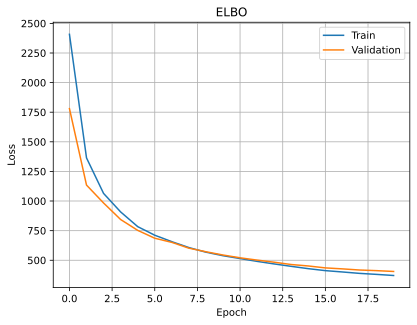

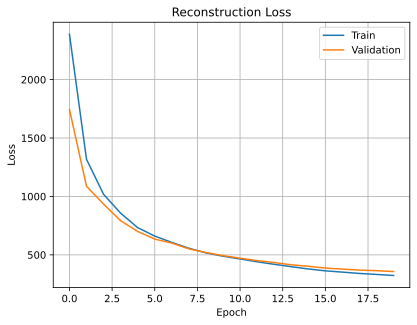

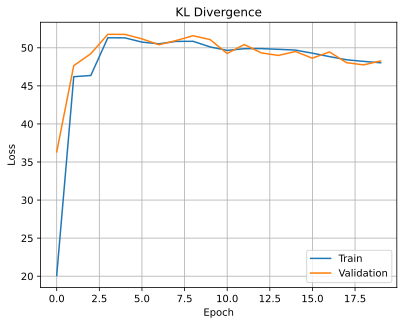

In [ ]:
import matplotlib.pyplot as plt

def plot_curves(train, val, title):
    plt.figure()
    plt.plot(train, label='Train')
    plt.plot(val, label='Validation')
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

plot_curves(train_elbos, val_elbos, "ELBO")
plot_curves(train_recons, val_recons, "Reconstruction Loss")
plot_curves(train_klds, val_klds, "KL Divergence")


The ELBO starts high and ends low  indicating improved model performance and better reconstructions. The training ELBO is very close to the final validation ELBO, suggesting that the model generalizes well to unseen data. Overall, the VAE successfully learned meaningful latent representations of handwritten digits. Worth pointing out the the KL divergence increased for the first 3 epochs then it starts decreasing.

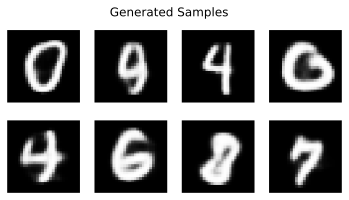

In [ ]:
# Generate and display samples from the model
samples = model.sample(8).cpu()

# Plot samples in a 2x4 grid
fig, axs = plt.subplots(2, 4, figsize=(6, 3)) # Changed grid to 2x4 and adjusted figure size
for i in range(2): # Changed loop range
    for j in range(4):
        axs[i, j].imshow(samples[i * 4 + j].squeeze(), cmap='gray')
        axs[i, j].axis('off')
plt.suptitle("Generated Samples")
plt.show()

The generated samples from the decoder gives readable handwrited digits, indicating that the model learned good.

In [ ]:
# digits we want to find examples for (you can customize this)
digits_needed = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

# dictionary to store the first index of each digit in the test set
first_indices = {}

# iterate over the test set to find the first occurrence of each digit
for idx, (img, label) in enumerate(test_set):
    # if we haven't stored this digit yet, save its index
    if label in digits_needed and label not in first_indices:
        first_indices[label] = idx

# print out the indices we found for each digit
print("First indices for digits:")
for digit, idx in first_indices.items():
    print(f"Digit {digit}: Index {idx}")

# now create pairs of digits for interpolation
pairs = [
    ((first_indices[0], 0), (first_indices[1], 1)),
    ((first_indices[8], 8), (first_indices[3], 3)),
    ((first_indices[9], 9), (first_indices[7], 7))
]
# print the pairs to check
print("Generated pairs:")
print(pairs)

First indices for digits:
Digit 7: Index 0
Digit 2: Index 1
Digit 1: Index 2
Digit 0: Index 3
Digit 4: Index 4
Digit 9: Index 7
Digit 5: Index 8
Digit 6: Index 11
Digit 3: Index 18
Digit 8: Index 61
Generated pairs:
[((3, 0), (2, 1)), ((61, 8), (18, 3)), ((7, 9), (0, 7))]


Interpolating between digits: 0 -> 1


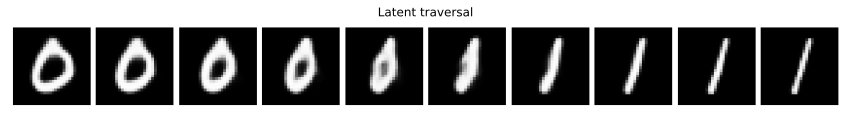

Interpolating between digits: 8 -> 3


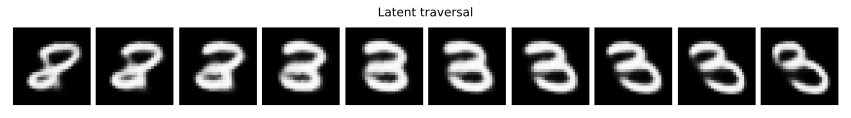

Interpolating between digits: 9 -> 7


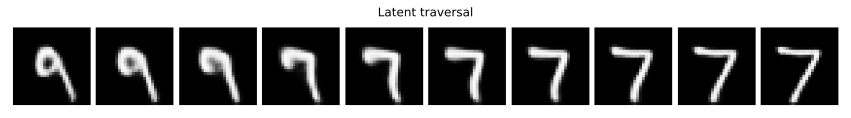

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.utils
import matplotlib.pyplot as plt

# get latent vector (mu) for one image
def get_latent_vactor(model, img):
  with torch.no_grad():
    mu, _, _ = model.encoder(img.unsqueeze(0).to(device))
    # Remove the batch dimension of size 1 before returning
    return mu.squeeze(0).cpu()

# compute linear interpolation between z1 and z2
def linear_interpolation(z1, z2, steps=10):
  # z1 and z2 should now be of shape (latent_dim,)
  return torch.stack([z1 + (z2 - z1) * i / (steps - 1) for i in range(steps)])


# visualize decoded images along the interpolation path
def visualize_travel(model, z_travel):
  with torch.no_grad():
    # z_travel is now of shape (steps, latent_dim)
    samples = model.decoder(z_travel.to(device))
    samples = samples.clamp(0, 1)
    grid = torchvision.utils.make_grid(samples, nrow=10, pad_value=128)
    grid = grid.clamp(0, 1)  # Add this to avoid clipping warnings
    plt.figure(figsize=(15, 3))
    # Move the grid tensor to CPU before plotting
    plt.imshow(grid.permute(1, 2, 0).cpu())
    plt.axis('off')
    plt.title("Latent traversal")
    plt.show()

# loop over pairs and show interpolation
for (idx1, digit1), (idx2, digit2) in pairs:
  img1, label1 = test_set[idx1]
  img2, label2 = test_set[idx2]
  print(f"Interpolating between digits: {label1} -> {label2}")
  z1 = get_latent_vactor(model, img1)
  z2 = get_latent_vactor(model, img2)
  z_travel = linear_interpolation(z1, z2, steps=10)
  visualize_travel(model, z_travel)

##Latent Space Traversals Explanation
In this part, we explored the latent space of the VAE by interpolating between two different digit images for each of three selected pairs of digits. For each pair:
We encoded the two digits to their latent representations (mu vectors).
We computed a linear interpolation of 10 steps between these two latent points.
At each step, we decoded the interpolated latent vector to visualize how the digit transitions from one digit to the other.

##For example:
Interpolating between 0 → 1 showed a smooth transformation from a "0" to a "1".
Interpolating between 8 → 3 smoothly blended the loop of "8" into the open curves of "3".
Interpolating between 9 → 7 demonstrated how a "9" gradually loses its loop to become a "7".
These traversals visually confirm that the latent space is smooth and meaningful — small changes in the latent space result in small, realistic changes in the decoded images. This is a key feature of a well-trained VAE, indicating that the encoder and decoder learned to map between data and latent representations effectively.

  0%|          | 0/79 [00:00<?, ?it/s]

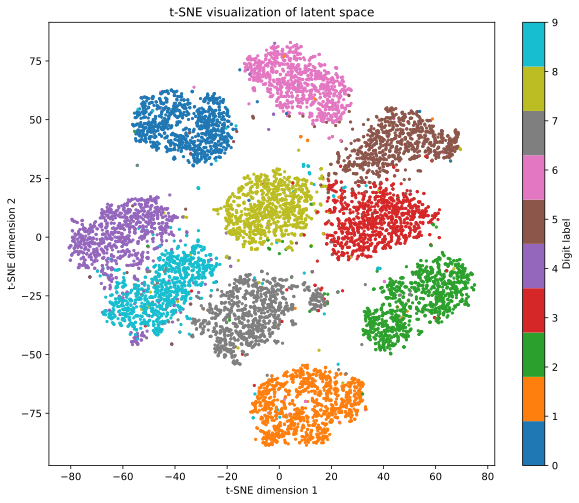

In [ ]:
from sklearn.manifold import TSNE as TNSE
from tqdm.notebook import tqdm # Import tqdm
import torch
import matplotlib.pyplot as plt

# get latent representations (mu) and labels for all images
def get_latent_representation(model, data_loader):
  zs = []
  labels = []
  model.eval()
  with torch.no_grad():
    for imgs, lbls in tqdm(data_loader):
      imgs = imgs.to(device)
      # Call the forward method of the VAE model to get mu, log_var, and z
      # Unpack all four returned values and only keep mu
      reconstruction, mu, log_var, z = model(imgs)  # Unpack all 4 values
      zs.append(mu.cpu()) # Move mu to CPU before appending
      labels.append(lbls)
  zs = torch.cat(zs, dim=0).numpy()  # combine all latent vectors
  labels = torch.cat(labels, dim=0).numpy()  # combine all labels
  return zs, labels

# compute latent representations for test set
test_zs, test_labels = get_latent_representation(model, test_loader)

# use t-SNE to project to 2D
tnse = TNSE(n_components=2, random_state=42, perplexity=30)
test_zs_2d = tnse.fit_transform(test_zs)

# plot 2D t-SNE projection
plt.figure(figsize=(10, 8))
scatter = plt.scatter(test_zs_2d[:, 0], test_zs_2d[:, 1], c=test_labels, cmap='tab10', s=5)
plt.colorbar(scatter, ticks=range(10), label='Digit label')
plt.title("t-SNE visualization of latent space")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.show()

##Latent Space Visualization Explanation :
In this section, we used t-SNE to project the high-dimensional latent representations (the means mu learned by the encoder) into 2D. The scatter plot shows the result of this projection:

Each point in the plot represents one digit image in the test set.

The color of each point corresponds to the true digit label, letting us see if the VAE has learned a meaningful latent structure.

Well-separated and coherent clusters for different digits indicate that the VAE learned to encode similar digits to nearby latent vectors. This suggests that the encoder’s learned latent space preserves important data characteristics, making it easier for the decoder to generate realistic images.

The resulting visualization confirms that the VAE’s latent space has meaningful structure — digits of the same class tend to cluster together in this space, and the clusters have smooth transitions.